In [44]:
import awkward as ak
import numba
import numpy as np
import pandas as pd
import awkward as ak
import vector
import torch
from scipy.special import softmax
vector.register_numba()
vector.register_awkward()
import os
from copy import deepcopy

import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import mplhep as hep
hep.style.use(hep.style.ROOT)

import numba
import h5py
import yaml

import seaborn as sns

from scipy.stats import norm
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.metrics import confusion_matrix
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix
import onnxruntime    # to inference ONNX models, we use the ONNX Runtime

In [2]:
CMAP_10 = [
    "#3f90da",
    "#ffa90e",
    "#bd1f01",
    "#94a4a2",
    "#832db6",
    "#a96b59",
    "#e76300",
    "#b9ac70",
    "#717581",
    "#92dadd",
]

COLOR_ALIASES = {
    "CMS_blue": CMAP_10[0],        # Blue
    "CMS_orange": CMAP_10[1],      # Orange
    "CMS_red": CMAP_10[2],         # Red
    "CMS_gray": CMAP_10[3],        # Gray
    "CMS_purple": CMAP_10[4],      # Purple
    "CMS_brown": CMAP_10[5],       # Brown
    "CMS_dark_orange": CMAP_10[6], # Dark Orange
    "CMS_beige": CMAP_10[7],       # Beige
    "CMS_dark_gray": CMAP_10[8],   # Dark Gray
    "CMS_light_blue": CMAP_10[9]   # Light Blue
}

colors = {
    "ttHbb": COLOR_ALIASES["CMS_red"],
    "ttbb": COLOR_ALIASES["CMS_dark_orange"],
    "ttcc": COLOR_ALIASES["CMS_orange"],
    "ttlf": COLOR_ALIASES["CMS_blue"],
    "ttV": COLOR_ALIASES["CMS_brown"],
    "singleTop": COLOR_ALIASES["CMS_purple"],
    "ttH_nobb": COLOR_ALIASES["CMS_light_blue"],
}

labels = {
    "ttHbb": 1, 
    "ttbb": 2,
    "ttcc": 3,
    "ttlf": 4,
    "ttV": 5,
    "singleTop": 6,
    "ttH_nobb": 7
}


labels_legend = {
    "ttHbb": r"$t\bar{t}$Hbb",
    "ttbb": r"$t\bar{t}b\bar{b}$",
    "ttcc": r"$t\bar{t}c\bar{c}$",
    "ttlf": r"$t\bar{t}$lf",
    "ttv": r"$t\bar{t}$V",
    "singletop": "Single top",
    "tthcc": r"$t\bar{t}$Hnon-bb",
}

In [3]:
out_folder = "/eos/home-g/gbonomel/projects/www/spanet/1L_channel/spanet_v0_noTriggerSFs"
onnx_model = "/eos/cms/store/group/phys_higgs/ttHbb/ntuples/ttHbb_export/training_5wps_multiplewp/no_triggerSF/semilep_channel/spanet_v0_1Lchannel.onnx"
h5_file = "/eos/cms/store/group/phys_higgs/ttHbb/ntuples/ttHbb_export/training_5wps_multiplewp/no_triggerSF/semilep_channel/h5_files/bkg_tthbb_genmatched_1L_test_1003068.h5"
config = "/eos/cms/store/group/phys_higgs/ttHbb/ntuples/ttHbb_export/training_5wps_multiplewp/no_triggerSF/semilep_channel/event.yaml"

In [4]:
def plot_score(pred_label, score, label, ax, weights=None, title=None, mask=None, log=False, ylim=None, density=False, legend=True):
    if type(mask) != type(None):
        pred_label = pred_label[mask]
        if type(weights) != type(None):
            weights = weights[mask]
    if label in colors:
        color = colors[label]
    else:
        color = ax._get_lines.get_next_color()
    #if label in nice_labels:
    #    label = nice_labels[label]
    n, bins, patches = ax.hist(pred_label, bins=50, range=(0,1), weights=weights, histtype="step", linewidth=2, color=color, label=label, density=density)
    if legend:
        ax.legend(fontsize=15)
    ax.set_xlabel(f"{score} SPANet score")
    if density:
        ax.set_ylabel("A.U.")
    else:
        ax.set_ylabel("Counts")
    if log:
        ax.set_yscale("log")
    if ylim != None:
        ax.set_ylim(*ylim)
    if title:
        ax.set_title(title)
    return n, bins, patches

def plot_scores(true_labels, pred_labels, plot_dir=None, weights=None, title=None, mask=None, log=False, ylim=None, density=False):
    fig, axes = plt.subplots(2, 4, figsize=[24,12], dpi=100)
    axes = axes.flatten()
    for i, score in enumerate(labels):
        ax = axes[i]
        for j, label in enumerate(labels):
            mask_by_sample = true_labels[label]
            if type(mask) != type(None):
                mask_by_sample = mask_by_sample & mask
            legend = True #if score == "tthbb" else False][0]         
            if type(weights) != type(None):
                plot_score(pred_labels[score], score, label, mask=mask_by_sample, ax=ax, weights=weights, title=title, log=log, ylim=ylim, density=density, legend=legend)
            else:
                plot_score(pred_labels[score], score, label, mask=mask_by_sample, ax=ax, title=title, log=log, ylim=ylim, density=density, legend=legend)
    # Hide empty subplot
    axes[-1].set_visible(False)
    fig.tight_layout(pad=1.5)
    if plot_dir is not None:
        filename = os.path.join(plot_dir, "classification_scores.png")
        if weights is not None:
            filename = filename.replace(".png", "_weighted.png")
        if log:
            filename = filename.replace(".png", "_log.png")
        if density:
            filename = filename.replace(".png", "_normalised.png")
        plt.savefig(filename, dpi=300)

In [42]:
def plot_confusion_matrix(y_true, y_pred, plot_dir=None, norm=None, class_names=None, title=None, cmap='Blues', weights=None):
    
    # Compute confusion matrix with optional sample weights
    cm = confusion_matrix(y_true, y_pred, normalize=norm, sample_weight=weights)[1:, 1:] #remove 1st col and row bc empty

    if class_names is not None:
        labels = [labels_legend.get(name, name) for name in class_names]
    else:
        labels = [labels_legend.get(i, i) for i in np.arange(cm.shape[0])]

    # Plotting
    plt.figure(figsize=(12, 12), dpi=100)
    ax = sns.heatmap(cm, annot=True, cmap=cmap, xticklabels=labels, yticklabels=labels, fmt=".2f")
    ax.set_title(title)
    ax.set_ylabel('True Label')
    ax.set_xlabel('Predicted Label')

    # force horizontal x tick labels and readable y ticks
    ax.set_xticklabels(ax.get_xticklabels(), rotation=0, ha='center', fontsize=18)
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=18)

    plt.tight_layout()

    if plot_dir is not None:
        if norm == "true":
            filename = os.path.join(plot_dir, "confusion_matrix_norm_true.png")
        elif norm == "pred":
            filename = os.path.join(plot_dir, "confusion_matrix_norm_pred.png")
        else:
            filename = os.path.join(plot_dir, "confusion_matrix.png")
        plt.savefig(filename, dpi=100)
    plt.show()


In [6]:
def plot_roc(true_label, pred_label, ax, label, weight=None, colors=None):
    """
    Plots a ROC curve and calculates the AUC.
    If sample weights are provided, only non-negative finite weights are used.
    """
    true_label = np.asarray(true_label, dtype=bool)
    pred_label = np.asarray(pred_label, dtype=float)

    if weight is not None:
        w = np.asarray(weight, dtype=float)
        valid = np.isfinite(pred_label) & np.isfinite(w)
        true_label = true_label[valid]
        pred_label = pred_label[valid]
        w = np.clip(w[valid], a_min=0.0, a_max=None)
        use = w > 0
        true_label = true_label[use]
        pred_label = pred_label[use]
        w = w[use]
    else:
        valid = np.isfinite(pred_label)
        true_label = true_label[valid]
        pred_label = pred_label[valid]
        w = None

    if true_label.size == 0 or np.unique(true_label).size < 2:
        ax.text(0.5, 0.5, "AUC undefined", ha="center", va="center", transform=ax.transAxes)
        ax.set_xlabel("False Positive Rate", fontsize=14)
        ax.set_ylabel("True Positive Rate", fontsize=14)
        #ax.set_title(f"{label} ROC Curve", fontsize=14)
        ax.grid(True)
        return

    fpr, tpr, _ = roc_curve(true_label, pred_label, sample_weight=w)

    try:
        auc = roc_auc_score(true_label, pred_label, sample_weight=w)
    except ValueError:
        auc = float("nan")

    if colors and label in colors:
        ax.plot(fpr, tpr, label=f"{labels_legend[label]} AUC={auc:.3f}", color=colors[label])
    else:
        ax.plot(fpr, tpr, label=f"{labels_legend[label]} AUC={auc:.3f}")
    ax.set_xlabel("False Positive Rate", fontsize=14)
    ax.set_ylabel("True Positive Rate", fontsize=14)
    #ax.set_title(f"{label} ROC Curve", fontsize=14)
    ax.legend()
    ax.grid(True)

def plot_rocs(true_labels, pred_labels, weight=None, plot_dir=None):
    """
    Plots ROC curves for all classes in the labels dictionary.
    """
    fig, axes = plt.subplots(3, 3, figsize=[18,16], dpi=100)
    axes = axes.flatten()
    
    for i, (score, label_index) in enumerate(labels.items()):
        ax = axes[i]
        true_label = true_labels[score]
        pred_label = pred_labels[score]
        plot_roc(true_label, pred_label, ax, score, weight=weight)

    # remove any unused subplots
    for ax in axes[len(labels):]:
        fig.delaxes(ax)

    fig.tight_layout(pad=2.5)
    if plot_dir is not None:
        filename = os.path.join(plot_dir, "roc_curves.png")
        plt.savefig(filename, dpi=300)


In [7]:
def plot_correlation_matrix(numpy_array, plot_dir, feature_names=None, title="Correlation Matrix", annot=True, cmap="coolwarm"):
    """
    Plots the correlation matrix from a NumPy array and saves it to a file.
        numpy_array (np.ndarray): A NumPy array of shape [N, M], where M is the
                                   number of features.
        output (str): Path to the output PNG file.
        feature_names (list of str, optional): List of feature names to be used as
                                               labels for the plot. Defaults to None.
        annot (bool, optional): Whether to display correlation coefficients in the
                                heatmap. Defaults to True.
    """

    #num_features = numpy_array.shape[1]
    if feature_names is None:
        feature_names = [f'Feature {i+1}' for i in range(num_features)]
    
    df = pd.DataFrame(numpy_array[:, 1:], columns=feature_names) # dont consider numpy_array[:,0] because empty
    corr_matrix = df.corr()

    # Create the heatmap
    plt.figure(figsize=(12, 12), dpi=100)
    sns.heatmap(corr_matrix, annot=annot, cmap=cmap, xticklabels=feature_names, yticklabels=feature_names)
    plt.title(title)
    #plt.tight_layout()

    if plot_dir is not None:
        filename = os.path.join(plot_dir, "correlation_matrix.png")
        plt.savefig(filename, dpi=100)
    plt.show()
    plt.close()

In [8]:
def plot_cumulative_significance(true_scores, scores, weights, signal_index=None, bins=30, range=(0, 1), xlabel="Threshold", ylabel="$S/\\sqrt{B}$", plot_dir=None):
    """
    Plots the significance (S/sqrt(B)) as a function of score or any other variable.
        true_score (np.ndarray): True class labels of shape (N,).
        out_score (np.ndarray): Array of classifier outputs with shape (N, num_classes).
        weights (np.ndarray): Event weights of shape (N,).
        signal_class (int): Class label to consider as signal (default=1).
        output_path (str, optional): Path to save the figure. If None, it will not save.
    """

    if signal_index is None:
        signal_index = 1

    class_index = scores.shape[1]

    # save true scores for signal and background
    true_signal = (true_scores == signal_index)
    true_bkg = ~true_signal
    pred_sig_scores = scores[:,signal_index]

    # save the output score for the signal events that are predicted as signal 
    pred_scores = np.argmax(scores, axis=1)
    is_signal_pred = (pred_scores == signal_index)
    score_pred_signal = scores[is_signal_pred,signal_index]

    true_scores_selected = true_scores[is_signal_pred]
    weights_selected = weights[is_signal_pred]

    # cumulative significance vs threshold
    thresholds = np.linspace(0, 1, 100)
    cum_significance_pred = np.zeros_like(thresholds, dtype=float)
    cum_significance_true = np.zeros_like(thresholds, dtype=float)
    
    for i, thr in enumerate(thresholds):
        pass_signal = score_pred_signal > thr
        pass_true_signal = (pred_sig_scores > thr) & true_signal
        pass_true_bkg = (pred_sig_scores > thr) & true_bkg

        S_true_cum = np.sum(weights[pass_true_signal])
        B_true_cum = np.sum(weights[pass_true_bkg])
        cum_significance_true[i] = S_true_cum / np.sqrt(B_true_cum) if B_true_cum > 0 else 0
        
        S_pred_cum = np.sum(weights_selected[pass_signal & (true_scores_selected == 1)])
        B_pred_cum = np.sum(weights_selected[pass_signal & (true_scores_selected != 1)])
        cum_significance_pred[i] = S_pred_cum / np.sqrt(B_pred_cum) if B_pred_cum > 0 else 0  
    
    fig, ax = plt.subplots(figsize=[10,8])
    ax.plot(thresholds, cum_significance_pred, marker='o', color=CMAP_10[0], linestyle='-', label="Predicted as ttHbb")
    ax.plot(thresholds, cum_significance_true, marker='o', color=CMAP_10[1], linestyle='-', label="ttHbb node")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title("Cumulative Significance")
    ax.legend(fontsize=15)

    if plot_dir is not None:
        filename = os.path.join(plot_dir, "cumulative_significance.png")
        plt.savefig(filename, dpi=300)
    plt.show()

In [9]:
def compute_s_over_sqrtb(y_true, scores, weights, signal_index=None, bins=30, range=(0, 1)):
    if signal_index is None:
        signal_index = 1
    if isinstance(bins, int):
        bins = np.linspace(range[0], range[1], bins + 1)
    bin_centers = 0.5 * (bins[:-1] + bins[1:])
    s_over_sqrtb = np.zeros(len(bin_centers))
    for i, (low, high) in enumerate(zip(bins[:-1], bins[1:])):
        in_bin = (scores >= low) & (scores < high)
        S = np.sum(weights[in_bin & (y_true==signal_index)])     # Signal in bin
        B = np.sum(weights[in_bin & (y_true!=signal_index)]) # Background in bin
        s_over_sqrtb[i] = S / np.sqrt(B) if B > 0 else 0
    return np.array(s_over_sqrtb)

In [43]:
class WeightedQuantileTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, n_quantiles=1000, output_distribution='normal'):
        self.n_quantiles = n_quantiles
        self.output_distribution = output_distribution

    def save(self, filename):
        np.savez(
            filename,
            quantiles=self.quantiles_,
            reference_quantiles=self.reference_quantiles_,
            n_quantiles=self.n_quantiles,
            output_distribution=self.output_distribution,
        )

    def load(self, filename):
        data = np.load(filename)
        self.quantiles_ = data["quantiles"]
        self.reference_quantiles_ = data["reference_quantiles"]
        self.n_quantiles = int(data["n_quantiles"])
        self.output_distribution = str(data["output_distribution"])
    
    def _weighted_quantiles(self, X, weights):
        # Calculate weighted quantiles
        sorted_indices = np.argsort(X)
        X_sorted = X[sorted_indices]
        weights_sorted = weights[sorted_indices]
        cum_weights = np.cumsum(weights_sorted) / np.sum(weights_sorted)
        
        # Interpolate to get quantiles
        quantiles = np.interp(np.linspace(0, 1, self.n_quantiles), cum_weights, X_sorted)
        return quantiles
    
    def fit(self, X, y=None, sample_weight=None):
        if sample_weight is None:
            raise ValueError("Sample weights must be provided.")
        
        self.quantiles_ = self._weighted_quantiles(X, sample_weight)
        
        if self.output_distribution == 'normal':
            self.reference_quantiles_ = norm.ppf(np.linspace(0, 1, self.n_quantiles))
        elif self.output_distribution == 'uniform':
            self.reference_quantiles_ = np.linspace(0, 1, self.n_quantiles)
        else:
            raise ValueError(f"Unknown output distribution '{self.output_distribution}'.")
        
        return self
    
    def transform(self, X):
        # Interpolate based on weighted quantiles
        transformed_X = np.interp(X, self.quantiles_, self.reference_quantiles_)
        return transformed_X

In [10]:
sess_options = onnxruntime.SessionOptions()

sess_options.intra_op_num_threads = 4
sess_options.intra_op_num_threads = 4
sess_options.execution_mode = onnxruntime.ExecutionMode.ORT_PARALLEL
sess_options.graph_optimization_level = onnxruntime.GraphOptimizationLevel.ORT_ENABLE_ALL


session = onnxruntime.InferenceSession(
    onnx_model, 
    sess_options = sess_options,
    providers=['CUDAExecutionProvider', 'CPUExecutionProvider']
)
for input in session.get_inputs():
    print(f"{input.name}, {input.shape}")
    
for output in session.get_outputs():
    print(f"{output.name}, {output.shape}")


Jet_data, ['batch_size', 'num_Jet', 6]
Jet_mask, ['batch_size', 'num_Jet']
Met_data, ['batch_size', 'num_Met', 2]
Met_mask, ['batch_size', 'num_Met']
Lepton_data, ['batch_size', 'num_Lepton', 4]
Lepton_mask, ['batch_size', 'num_Lepton']
Event_data, ['batch_size', 'num_Event', 1]
Event_mask, ['batch_size', 'num_Event']
t1_assignment_probability, ['Expt1_assignment_probability_dim_0', 'Expt1_assignment_probability_dim_1', 'Expt1_assignment_probability_dim_2', 'Expt1_assignment_probability_dim_3']
t2_assignment_probability, ['Expt2_assignment_probability_dim_0', 'Expt2_assignment_probability_dim_1']
h_assignment_probability, ['Exph_assignment_probability_dim_0', 'Exph_assignment_probability_dim_1', 'Exph_assignment_probability_dim_2']
t1_detection_probability, ['Sigmoidt1_detection_probability_dim_0']
t2_detection_probability, ['Sigmoidt2_detection_probability_dim_0']
h_detection_probability, ['Sigmoidh_detection_probability_dim_0']
EVENT/signal, ['SoftmaxEVENT/signal_dim_0', 8]


/afs/cern.ch/work/g/gbonomel/envs/jupy/lib/python3.11/site-packages/onnxruntime/capi/onnxruntime_inference_collection.py:69: UserWarning: Specified provider 'CUDAExecutionProvider' is not in available provider names.Available providers: 'CPUExecutionProvider'
  warnings.warn(


In [11]:
f = h5py.File(h5_file, 'r')
f.keys()

<KeysViewHDF5 ['CLASSIFICATIONS', 'INPUTS', 'TARGETS', 'WEIGHTS']>

In [12]:
jet_data = f["INPUTS"]["Jet"]
met_data = f["INPUTS"]["Met"]
lepton_data = f["INPUTS"]["Lepton"]
event_data = f["INPUTS"]["Event"]
weights = f["WEIGHTS"]["weight"]

In [13]:
weights[()]

array([0.0590037 , 0.00011856, 0.09090899, ..., 0.0220439 , 0.00042625,
       0.00095918], dtype=float32)

In [14]:
with open(config, 'r') as file:
    data = yaml.safe_load(file)

jet_inputs    = list(data['INPUTS']['SEQUENTIAL']['Jet'].keys())
met_inputs    = data['INPUTS']['GLOBAL']['Met']
lepton_inputs = data['INPUTS']['GLOBAL']['Lepton']
event_inputs  = data['INPUTS']['GLOBAL']['Event']    

In [49]:
met_inputs, lepton_inputs, event_inputs

({'pt': 'log_normalize', 'phi': 'normalize'},
 {'pt': 'log_normalize',
  'eta': 'normalize',
  'phi': 'normalize',
  'pdgId': 'none'},
 {'ht': 'log_normalize'})

In [16]:
jet_data

<HDF5 group "/INPUTS/Jet" (9 members)>

In [17]:
jet_input = np.stack([jet_data[j][()] for j in jet_inputs], axis=2)
met_input = np.stack([met_data[j][()] for j in met_inputs], axis=1)[:,None,:]
lepton_input = np.stack([lepton_data[j][()] for j in lepton_inputs], axis=1)[:,None,:]
event_input = np.stack([event_data[j][()] for j in event_inputs], axis=1)[:,None,:]

In [18]:
event_input.shape

(1003068, 1, 1)

In [19]:
met_input.shape

(1003068, 1, 2)

In [20]:
jet_input[:,:,0] = np.log(1+ jet_input[:,:,0])
met_input[:,:,0] = np.log(1+ met_input[:,:,0])
lepton_input[:,:,0] = np.log(1+ lepton_input[:,:,0])
event_input[:,:,0] = np.log(1+ event_input[:,:,0])

In [21]:
jet_mask = jet_data["MASK"][()]
met_mask = np.ones(shape=[met_input.shape[0], 1]) == 1
lepton_mask = met_mask
event_mask = met_mask

In [22]:
met_mask.shape

(1003068, 1)

In [23]:
batch_size = 2048

In [24]:
Nevents = jet_input.shape[0]
cl_out= np.empty((Nevents, 8))

for i in range(Nevents//batch_size):
    output = session.run(input_feed={
        "Jet_data": jet_input[i*batch_size: (i+1)*batch_size],
        "Jet_mask": jet_mask[i*batch_size: (i+1)*batch_size],
        "Met_data": met_input[i*batch_size: (i+1)*batch_size],
        "Met_mask": met_mask[i*batch_size: (i+1)*batch_size],
        "Lepton_data": lepton_input[i*batch_size: (i+1)*batch_size],
        "Lepton_mask": lepton_mask[i*batch_size: (i+1)*batch_size],
        "Event_data": event_input[i*batch_size: (i+1)*batch_size],
        "Event_mask": event_mask[i*batch_size: (i+1)*batch_size],
        }, output_names=["EVENT/signal"]
               )
    cl_out[i*batch_size: (i+1)*batch_size] = output[0]

IndexError: index 5 is out of bounds for axis 1 with size 5

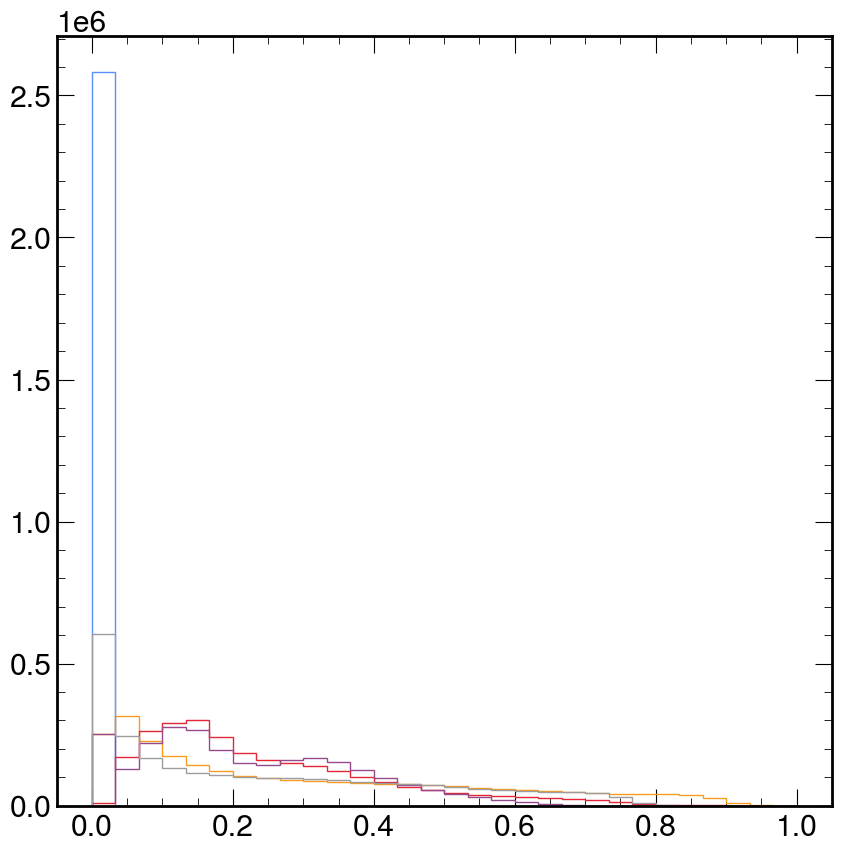

In [25]:
for i in range(7):
    plt.hist(cl_out[:,i], range=(0,1), bins=30, histtype='step', label=f"{i}")
plt.legend()
#plt.hist(cl_out[:,0])SoftmaxEVENT

(array([3.58829e+05, 1.85085e+05, 1.24470e+05, 1.13339e+05, 8.96800e+04,
        6.06850e+04, 4.18200e+04, 2.34980e+04, 5.45900e+03, 2.03000e+02]),
 array([0.        , 0.08417002, 0.16834004, 0.25251006, 0.33668008,
        0.4208501 , 0.50502012, 0.58919014, 0.67336016, 0.75753018,
        0.8417002 ]),
 <BarContainer object of 10 artists>)

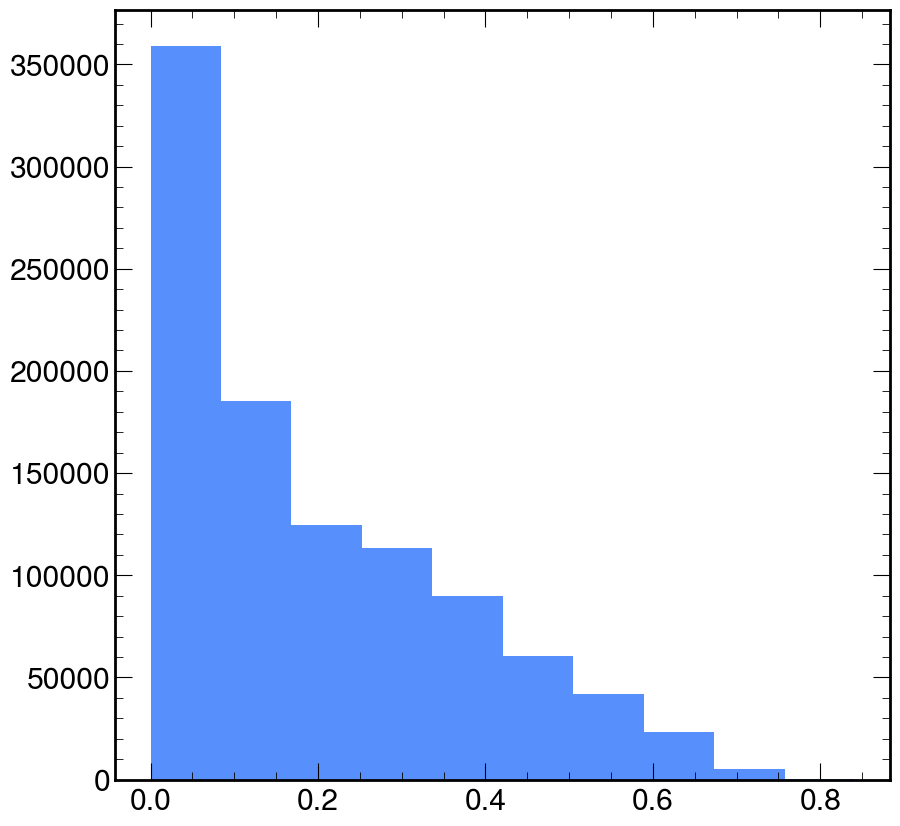

In [25]:
plt.hist(cl_out[:,1])

(array([2.29666e+05, 3.43587e+05, 2.00886e+05, 1.35356e+05, 6.03250e+04,
        2.42300e+04, 7.50200e+03, 1.29500e+03, 1.98000e+02, 2.30000e+01]),
 array([0.        , 0.07909592, 0.15819184, 0.23728775, 0.31638367,
        0.39547959, 0.47457551, 0.55367143, 0.63276734, 0.71186326,
        0.79095918]),
 <BarContainer object of 10 artists>)

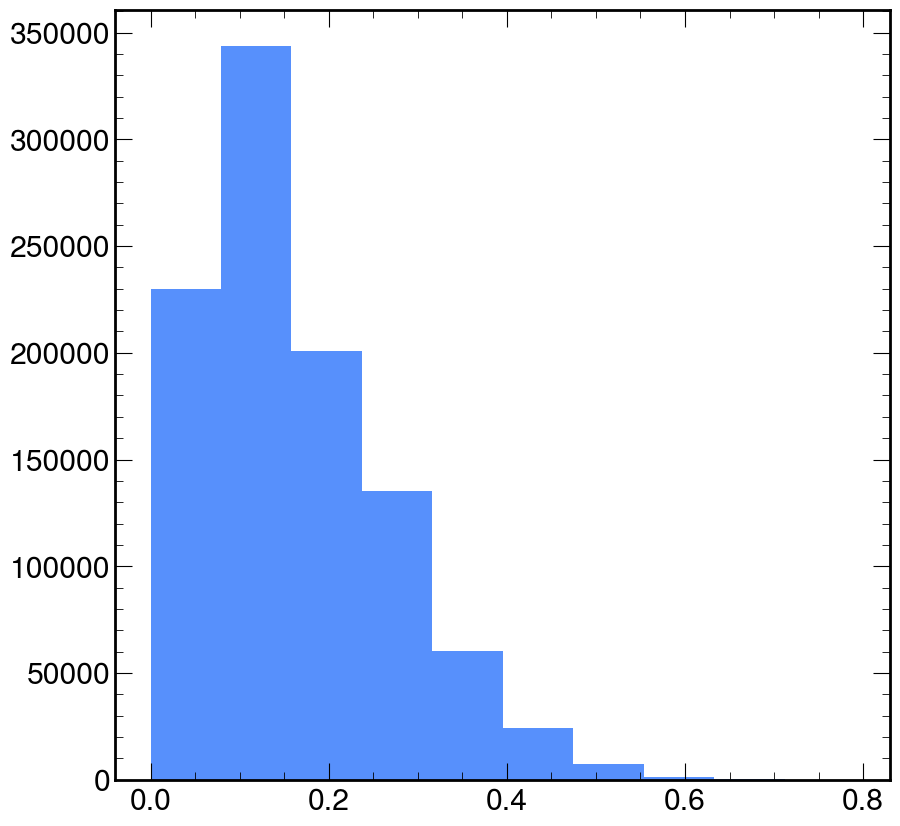

In [26]:
plt.hist(cl_out[:,2])

In [ ]:
f.keys()

In [28]:
y_true = f["CLASSIFICATIONS"]["EVENT"]["signal"][()]

In [29]:
y_pred = np.argmax(cl_out, axis=1)

In [27]:
y_true

NameError: name 'y_true' is not defined

In [29]:
cl_out.shape[1]

5

In [30]:
true_labels = {}
pred_labels = {}
for label, index in labels.items():
    true_labels[label] = np.array(y_true == index)
    pred_labels[label] = np.array(cl_out[:,index])

In [31]:
true_labels

{'ttHbb': array([False,  True, False, ..., False,  True,  True]),
 'ttbb': array([False, False, False, ..., False, False, False]),
 'ttcc': array([ True, False, False, ..., False, False, False]),
 'ttlf': array([False, False,  True, ...,  True, False, False]),
 'ttV': array([False, False, False, ..., False, False, False]),
 'singleTop': array([False, False, False, ..., False, False, False]),
 'ttH_nobb': array([False, False, False, ..., False, False, False])}

In [32]:
cl_out[:,1]

array([0.17736076, 0.31050116, 0.58062243, ..., 0.        , 0.        ,
       0.        ])

In [32]:
region_mask = np.argmax(cl_out, axis=1) == 1
region_mask.shape

(2807348,)

In [33]:
true_labels["ttHbb"]

array([False, False,  True, ...,  True, False, False])

In [42]:
pred_labels

{'ttHbb': array([0.17736076, 0.31050116, 0.58062243, ..., 0.        , 0.        ,
        0.        ]),
 'ttbb': array([0.12927511, 0.37827584, 0.29637012, ..., 0.        , 0.        ,
        0.        ]),
 'ttcc': array([0.45820999, 0.11078527, 0.08503793, ..., 0.        , 0.        ,
        0.        ]),
 'ttlf': array([0.23515418, 0.20043775, 0.03796946, ..., 0.        , 0.        ,
        0.        ])}

(array([523780., 569719., 286822., 181361., 160497., 185031., 256989.,
        343946., 236015.,  63188.]),
 array([0.        , 0.09681578, 0.19363155, 0.29044733, 0.38726311,
        0.48407888, 0.58089466, 0.67771044, 0.77452621, 0.87134199,
        0.96815777]),
 <BarContainer object of 10 artists>)

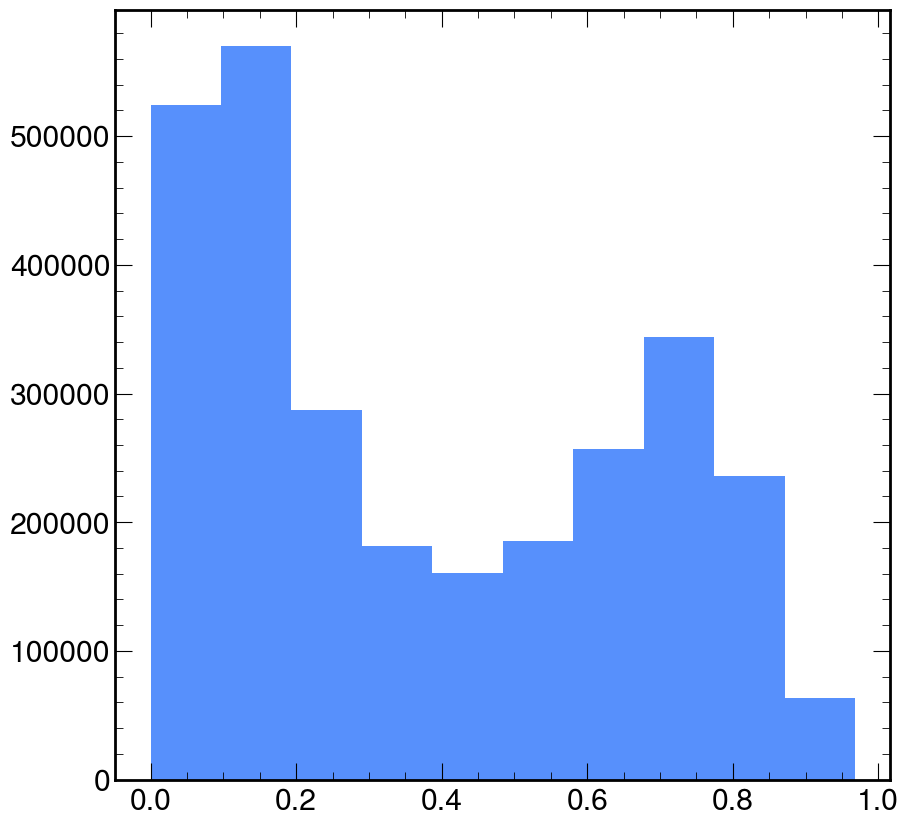

In [41]:
plt.hist(pred_labels["ttbb"])

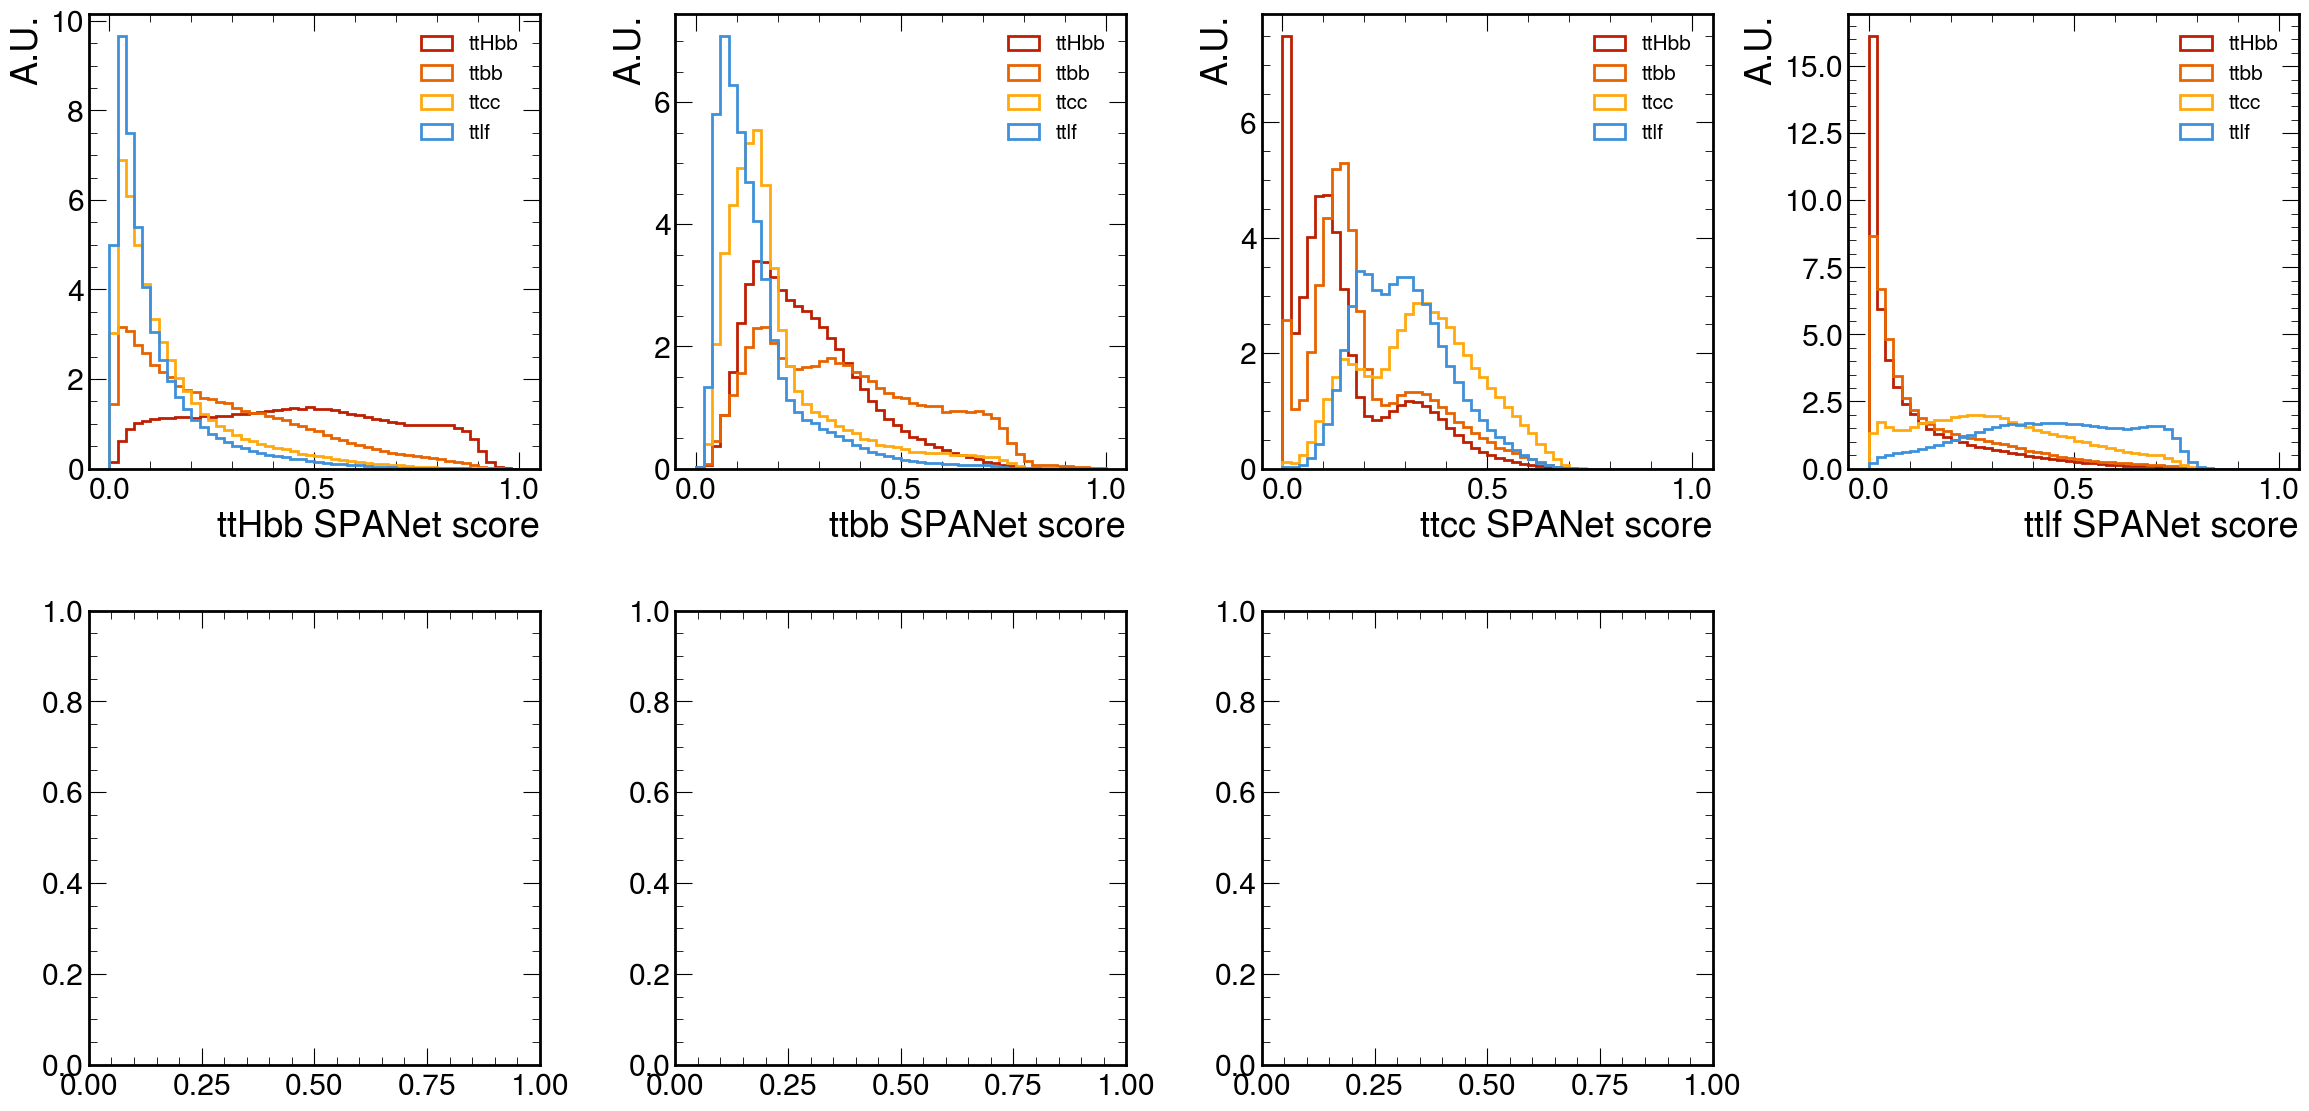

In [44]:
plot_scores(true_labels, pred_labels, weights=weights, plot_dir=out_folder, density=True) # mask by sample

IndexError: index 2 is out of bounds for axis 0 with size 2

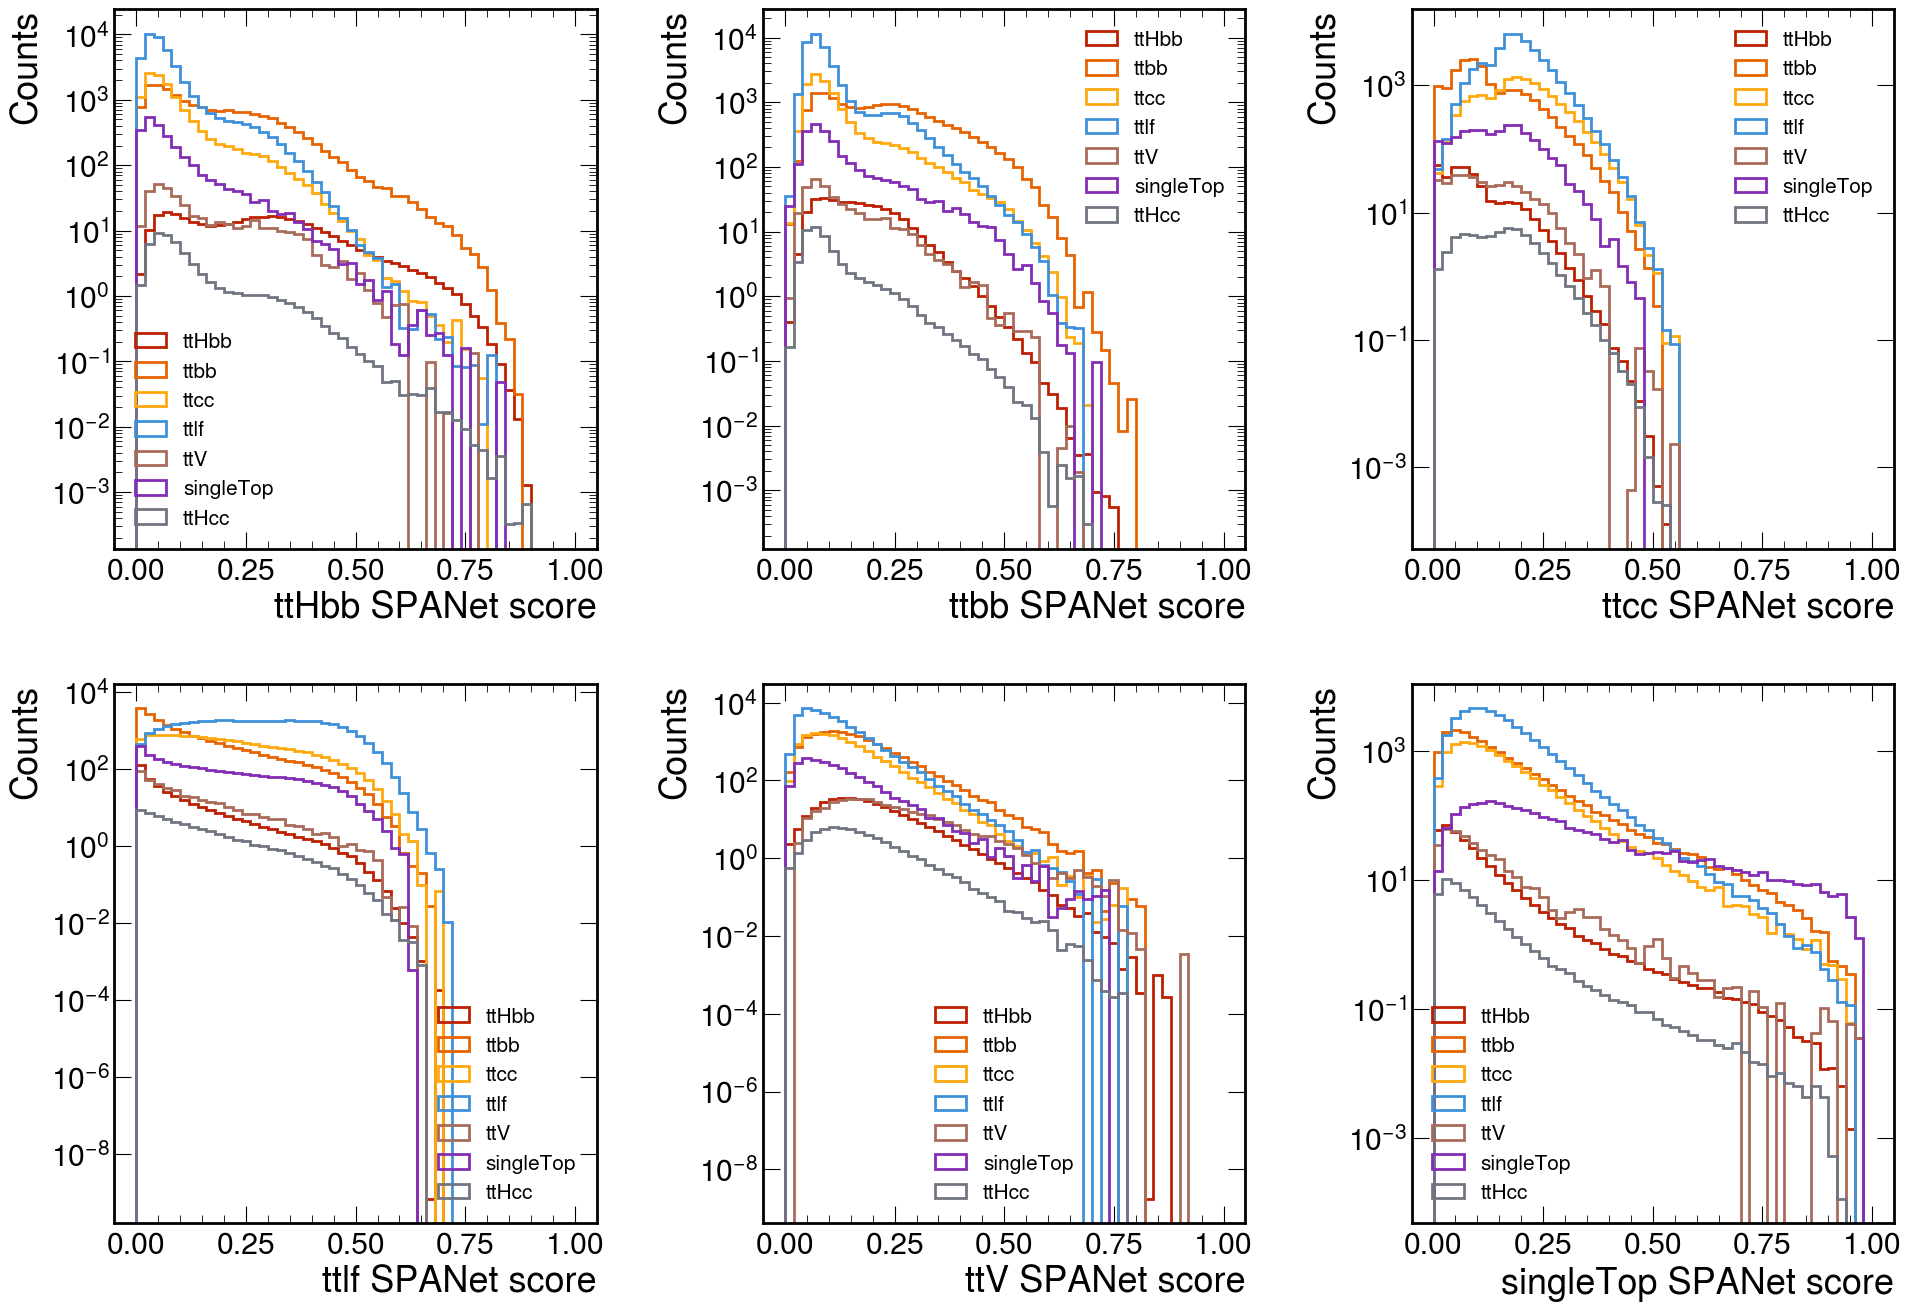

In [37]:
plot_scores(true_labels, pred_labels, weights=weights, plot_dir=out_folder, log=True) # mask by sample

In [ ]:
fig, axs = plt.subplots(2, 3, figsize=(18, 10), dpi=100)
axs = axs.flatten()
for i, (score, class_index) in enumerate(labels.items()):
    ax = axs[i]
    region_mask = np.argmax(cl_out, axis=1) == class_index
    for label, label_index in labels.items():
        mask = y_true == label_index
        color = colors[label]
        ax.hist(cl_out[mask & region_mask, class_index],
                bins=50, range=(0, 1),
                weights=weights[mask & region_mask],
                histtype="step", linewidth=2,
                color=color, label=label, density=True)
    ax.set_xlabel(f"{score} SPANet score")
    ax.set_ylabel("Counts")
    ax.legend(fontsize=15)
plt.tight_layout()
plt.savefig(out_folder + "classification_scores_pred_region_weighed_normalised.png", dpi=300)
plt.show()

IndexError: index 6 is out of bounds for axis 0 with size 6

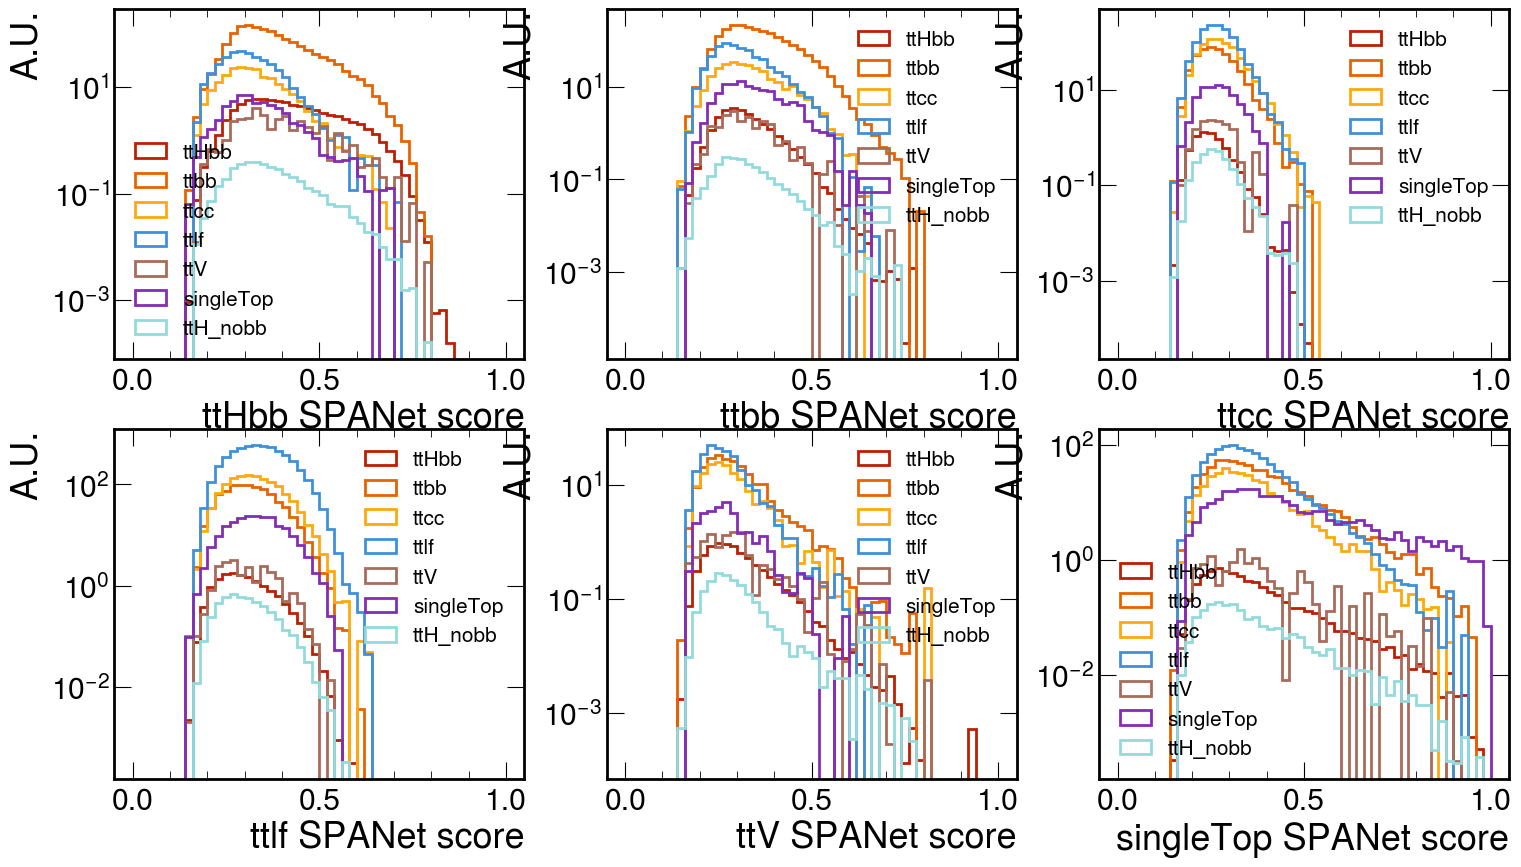

In [37]:
fig, axs = plt.subplots(2, 3, figsize=(18, 10), dpi=100)
axs = axs.flatten()
for i, (score, class_index) in enumerate(labels.items()):
    ax = axs[i]
    region_mask = np.argmax(cl_out, axis=1) == class_index
    for label, label_index in labels.items():
        mask = y_true == label_index
        color = colors[label]
        ax.hist(cl_out[mask & region_mask, class_index],
                bins=50, range=(0, 1),
                weights=weights[mask & region_mask],
                histtype="step", linewidth=2,
                color=color, label=label)
    ax.set_xlabel(f"{score} SPANet score")
    ax.set_ylabel("A.U.")
    ax.set_yscale("log")
    ax.legend(fontsize=15)
plt.tight_layout()
plt.savefig(out_folder + "classification_scores_pred_region_weighed_log.png", dpi=300)
plt.show()

KeyError: 'ttV'

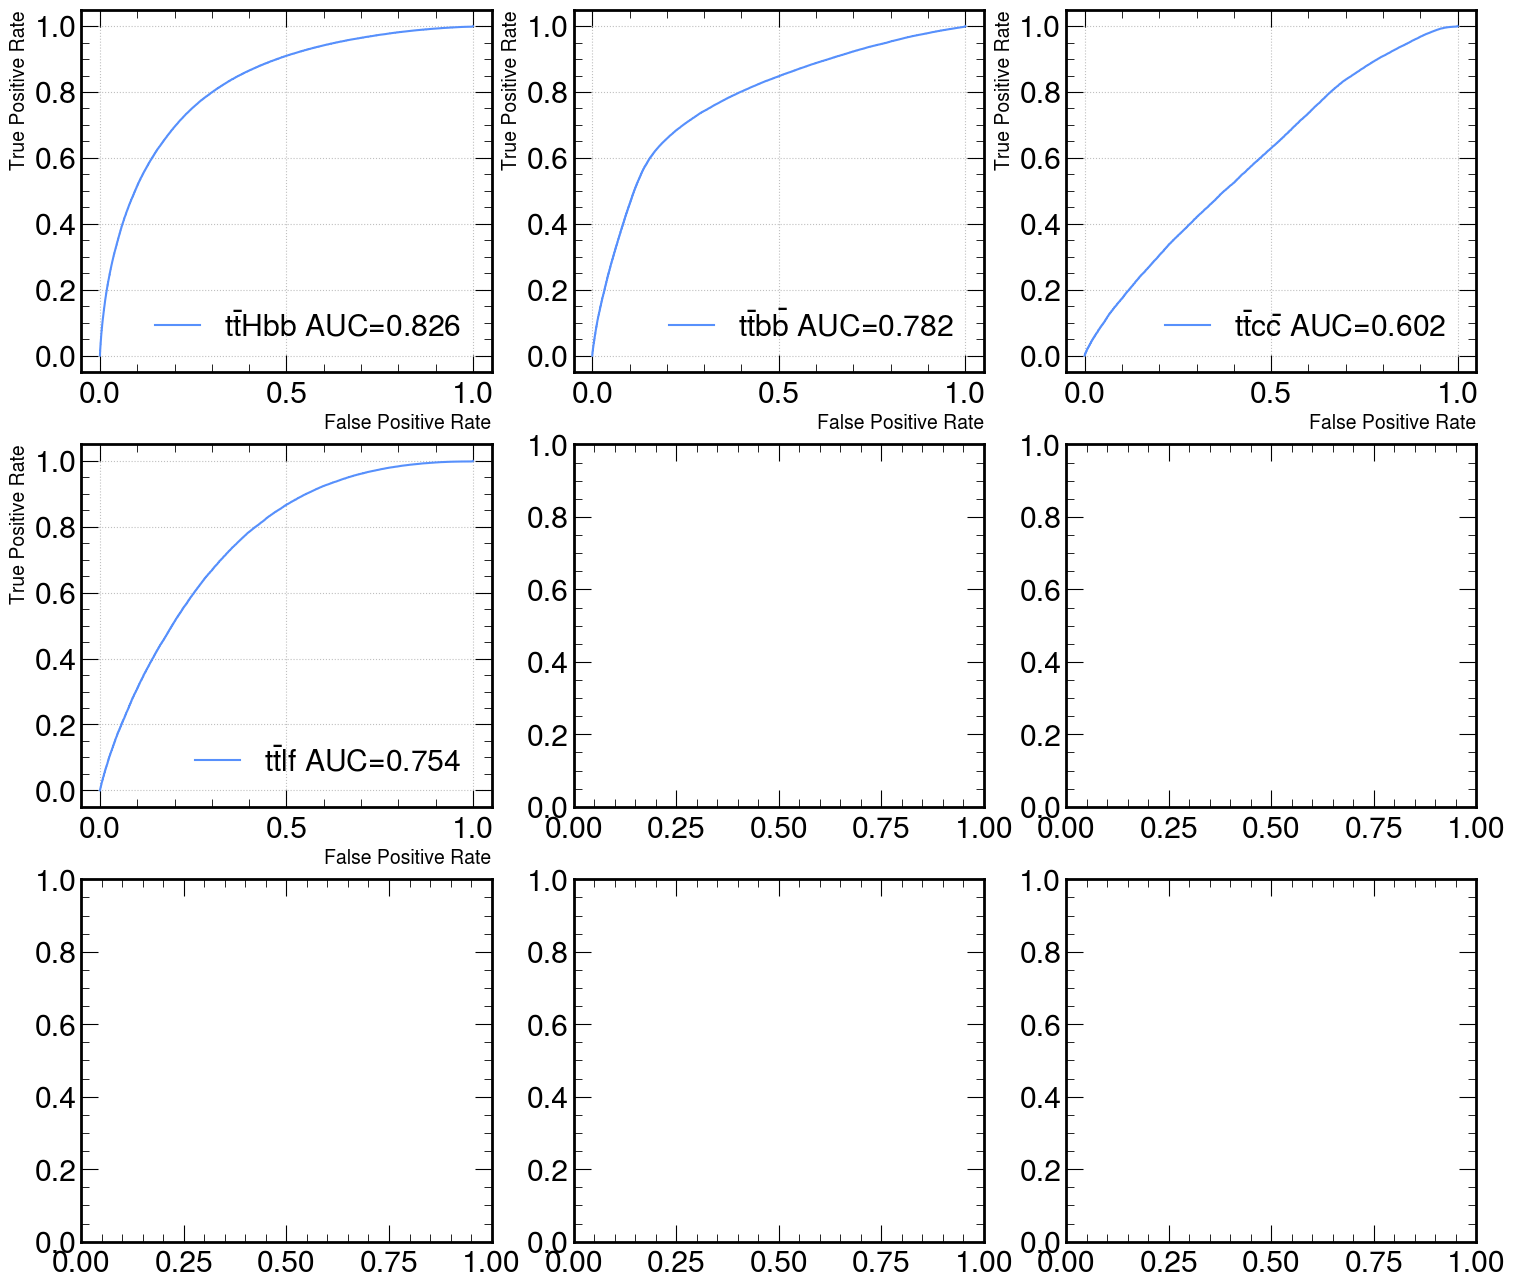

In [38]:
plot_rocs(true_labels, pred_labels, plot_dir=out_folder, weight=weights[:])

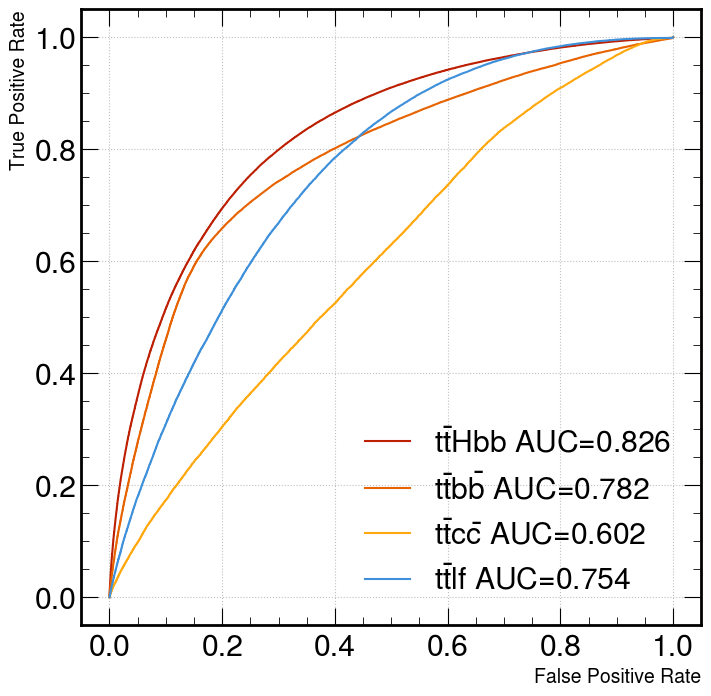

In [39]:
fig, ax = plt.subplots(1,1, figsize=[8,8])
plot_roc(true_labels["ttHbb"], pred_labels["ttHbb"], ax, label="ttHbb", weight=weights, colors=colors) 
plot_roc(true_labels["ttbb"], pred_labels["ttbb"], ax, label="ttbb", weight=weights, colors=colors) 
plot_roc(true_labels["ttcc"], pred_labels["ttcc"], ax, label="ttcc", weight=weights, colors=colors)
plot_roc(true_labels["ttlf"], pred_labels["ttlf"], ax, label="ttlf", weight=weights, colors=colors)
fig.savefig(os.path.join(out_folder, "roc_curve_tthbb_vs_bkg.png"), dpi=300)

In [ ]:
signal_index = labels["ttHbb"]
n_bin = 50
bins = np.linspace(0, 1, n_bin+1)
bin_centers = 0.5 * (bins[:-1] + bins[1:])
predicted_as_signal = (y_pred == signal_index)
y_true_predicted_signal = y_true[predicted_as_signal]
scores_predicted_signal = cl_out[predicted_as_signal, signal_index]
weights_predicted_signal = weights[predicted_as_signal]
s_over_sqrtb_tthbb = compute_s_over_sqrtb(y_true_predicted_signal, scores_predicted_signal, weights_predicted_signal, bins=n_bin)
s_over_sqrtb = compute_s_over_sqrtb(y_true, cl_out[:, signal_index], weights, bins=n_bin)
fig, ax = plt.subplots(figsize=[10,8])
ax.plot(bin_centers, s_over_sqrtb_tthbb, marker='o', color=CMAP_10[0], linestyle='-', label="Predicted as ttHbb")
ax.plot(bin_centers, s_over_sqrtb, marker='o', color=CMAP_10[1], linestyle='-', label="ttHbb node")
ax.set_xlabel("Bins")
ax.set_ylabel("$S/\\sqrt{B}$")
ax.legend(fontsize=15)
fig.savefig(out_folder + "signal_significance.png", dpi=100)

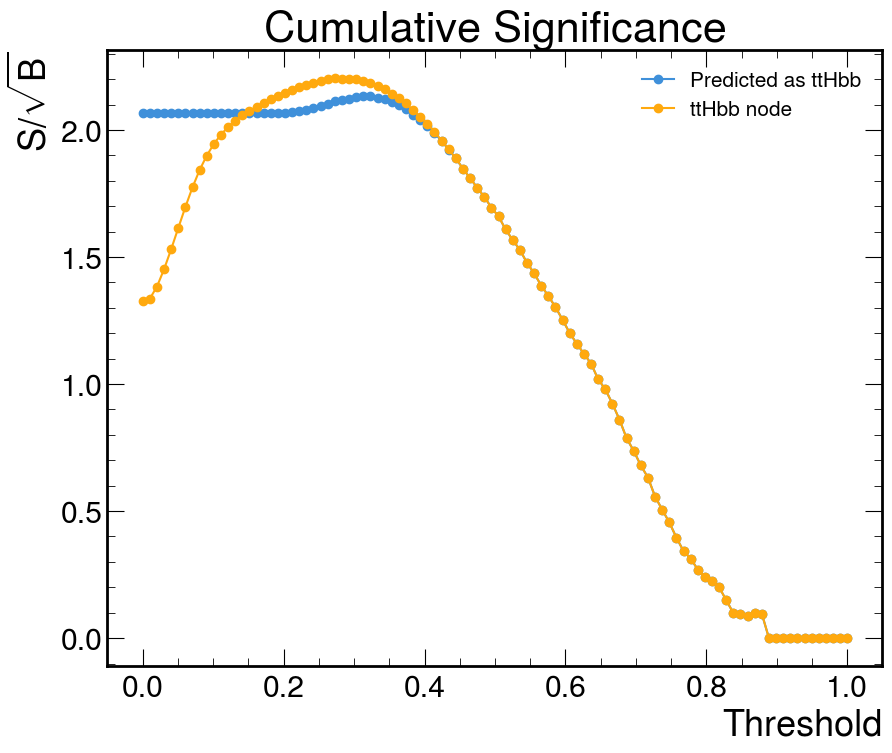

In [40]:
plot_cumulative_significance(y_true, cl_out, weights, plot_dir=out_folder)

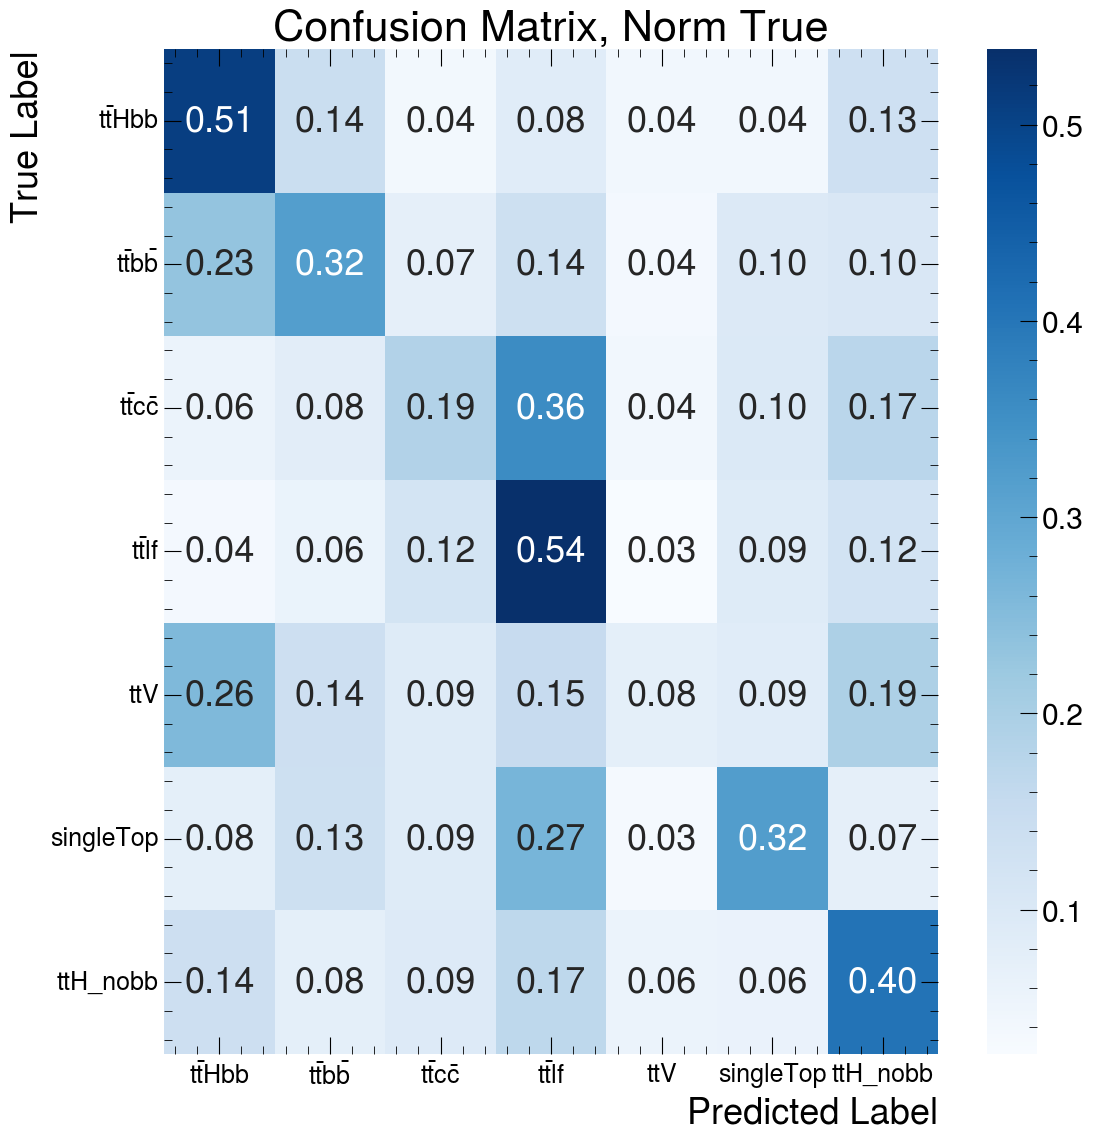

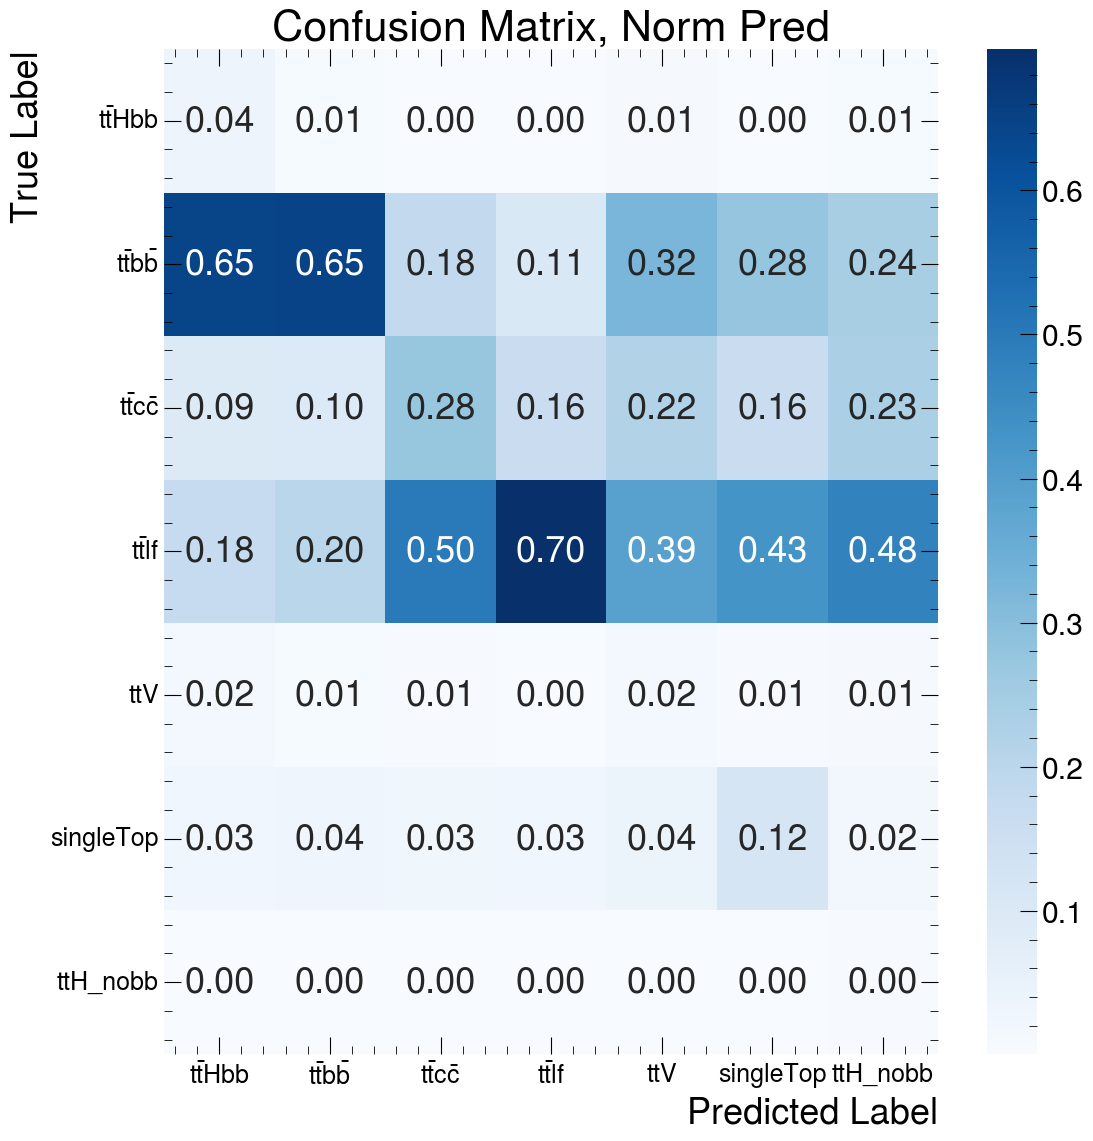

In [36]:
plot_confusion_matrix(y_true, y_pred, plot_dir=out_folder, norm="true", title="Confusion Matrix, Norm True", class_names=labels, weights=weights)
plot_confusion_matrix(y_true, y_pred, plot_dir=out_folder, norm="pred", title="Confusion Matrix, Norm Pred", class_names=labels, weights=weights)

In [ ]:
for label, class_index in labels.items():
    mask = y_true == class_index
    plot_correlation_matrix(cl_out[mask], plot_dir=out_folder, feature_names=labels.keys(), title=f"{label} Correlation Matrix")

In [46]:
is_tthbb = true_labels["ttHbb"]
score_tthbb = ak.to_numpy(pred_labels["ttHbb"][is_tthbb])
weights_tthbb = ak.to_numpy(weights[is_tthbb])
pred_labels_transformed = deepcopy(pred_labels)
transformer = WeightedQuantileTransformer(n_quantiles=10000, output_distribution='uniform')
transformer.fit(score_tthbb, sample_weight=weights_tthbb)
transformer.save("tthbb_quantile_transformer.npz")
pred_labels_transformed["ttHbb"] = ak.to_numpy(transformer.transform(pred_labels["ttHbb"]))

Text(0, 1, 'Counts')

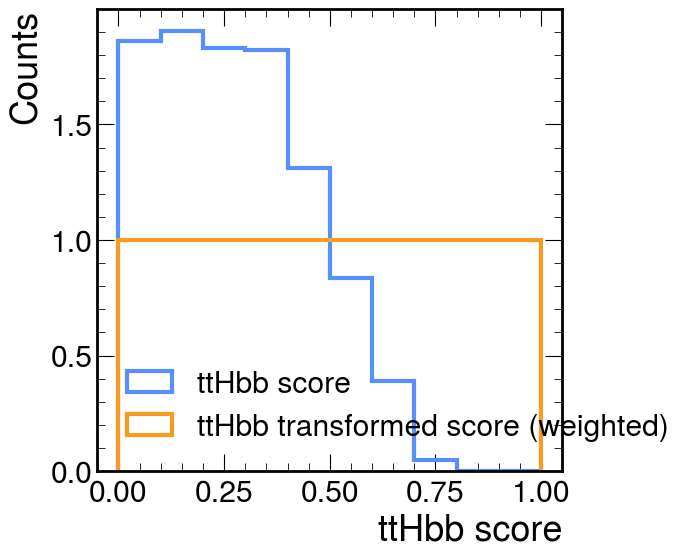

In [48]:
fig, ax = plt.subplots(1,1, figsize=[6,6])
ax.hist(pred_labels["ttHbb"][is_tthbb], weights=weights[is_tthbb], bins=10, range=(0,1), histtype="step", linewidth=3, label="ttHbb score", density=True)
ax.hist(pred_labels_transformed["ttHbb"][is_tthbb], weights=weights[is_tthbb], bins=10, range=(0,1), histtype="step", linewidth=3, label="ttHbb transformed score (weighted)", density=True)
ax.legend(loc='best');
ax.set_xlabel("ttHbb score")
ax.set_ylabel("Counts")